# Exploración del featured RoCoLe

Objetivo: revisar la tabla de características (índices RGB y textura GLCM), chequear calidad, mirar outliers univariados, comparar sanas y afectadas en train, y documentar la decisión sobre VARI. No entrenamos modelos aquí.


Fijamos la semilla para que lo que corramos después sea reproducible.


In [26]:
# Entrada
# ninguna

# Qué hacemos
seed = 42

# Salida
seed


42

Apuntamos a la tabla featured de RoCoLe (índices RGB y GLCM).


In [27]:
# Entrada
from pathlib import Path

# Qué hacemos
repo_root = Path("../..").resolve()
features_path = repo_root / "data" / "featured" / "rocole" / "rgb_glcm_features.csv"
results_dir = repo_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Salida
print("features_path:", features_path)
print("existe:", features_path.exists())
features_path


features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features.csv
existe: True


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/data/featured/rocole/rgb_glcm_features.csv')

Leemos la tabla: una fila por hoja, con etiqueta y medidas.


In [28]:
# Entrada
import pandas as pd

# Qué hacemos
leaf_features = pd.read_csv(features_path)

# Salida
leaf_features.head()


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


Miramos cuántas filas y columnas hay, y las primeras filas.


In [29]:
# Entrada
# leaf_features

# Qué hacemos
print("forma:", leaf_features.shape)
print("columnas:", list(leaf_features.columns))

# Salida
leaf_features.head()


forma: (1481, 15)
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


Revisamos si el mismo archivo aparece más de una vez. Si hay duplicados en File, hay que mirarlos antes de seguir.


In [30]:
# Entrada
# leaf_features

# Qué hacemos
duplicate_files = leaf_features.loc[leaf_features["File"].duplicated(keep=False)].copy()

# Salida
print("filas con File repetido:", len(duplicate_files))
print("Files únicos duplicados:", duplicate_files["File"].nunique() if len(duplicate_files) else 0)
duplicate_files.head()


filas con File repetido: 0
Files únicos duplicados: 0


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy


Apartamos las nueve medidas numéricas (ExG, NGRDI, VARI y GLCM). Las etiquetas quedan fuera de esta lista.


In [31]:
# Entrada
# leaf_features

# Qué hacemos
quality_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "vari_mean",
    "vari_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]
measure_columns = quality_columns.copy()

# Salida
quality_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'vari_mean',
 'vari_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

Contamos nulos por columna en toda la tabla, con foco en las nueve medidas.


In [32]:
# Entrada
import numpy as np

# Qué hacemos
null_counts = leaf_features.isna().sum()
missing_counts_all = leaf_features[quality_columns].isna().sum()

# Salida
print("nulos en toda la tabla:")
print(null_counts)
print("\nnulos en las nueve medidas:")
print(missing_counts_all)
missing_counts_all


nulos en toda la tabla:
File                   0
split                  0
link_group             0
Binary.Label           0
Multiclass.Label       0
error               1481
exg_mean               0
exg_std                0
ngrdi_mean             0
ngrdi_std              0
vari_mean              0
vari_std               0
glcm_contrast          0
glcm_homogeneity       0
glcm_energy            0
dtype: int64

nulos en las nueve medidas:
exg_mean            0
exg_std             0
ngrdi_mean          0
ngrdi_std           0
vari_mean           0
vari_std            0
glcm_contrast       0
glcm_homogeneity    0
glcm_energy         0
dtype: int64


exg_mean            0
exg_std             0
ngrdi_mean          0
ngrdi_std           0
vari_mean           0
vari_std            0
glcm_contrast       0
glcm_homogeneity    0
glcm_energy         0
dtype: int64

Contamos valores no finitos (infinitos o NaN) en las nueve medidas.


In [33]:
# Entrada
# leaf_features, quality_columns

# Qué hacemos
infinite_counts_all = {
    column: int((~np.isfinite(leaf_features[column])).sum())
    for column in quality_columns
}

# Salida
print("no finitos por medida:")
for column, count in infinite_counts_all.items():
    print(f"  {column}: {count}")
infinite_counts_all


no finitos por medida:
  exg_mean: 0
  exg_std: 0
  ngrdi_mean: 0
  ngrdi_std: 0
  vari_mean: 0
  vari_std: 0
  glcm_contrast: 0
  glcm_homogeneity: 0
  glcm_energy: 0


{'exg_mean': 0,
 'exg_std': 0,
 'ngrdi_mean': 0,
 'ngrdi_std': 0,
 'vari_mean': 0,
 'vari_std': 0,
 'glcm_contrast': 0,
 'glcm_homogeneity': 0,
 'glcm_energy': 0}

Miramos la distribución de ExG (exg_mean, exg_std) con diagramas de caja. Solo observamos; no cortamos outliers.


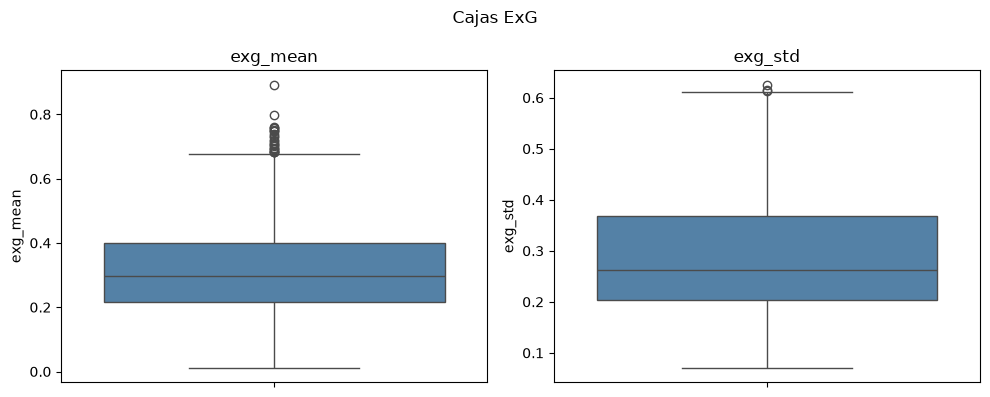

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-exg-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-exg-boxplots.png')

In [34]:
# Entrada
import matplotlib.pyplot as plt
import seaborn as sns

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas ExG")
fig.tight_layout()
exg_box_path = results_dir / "rocole-featured-exg-boxplots.png"
fig.savefig(exg_box_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", exg_box_path)
exg_box_path


Misma mirada univariada de ExG en dispersión: cada punto es una hoja (eje x = índice de fila).


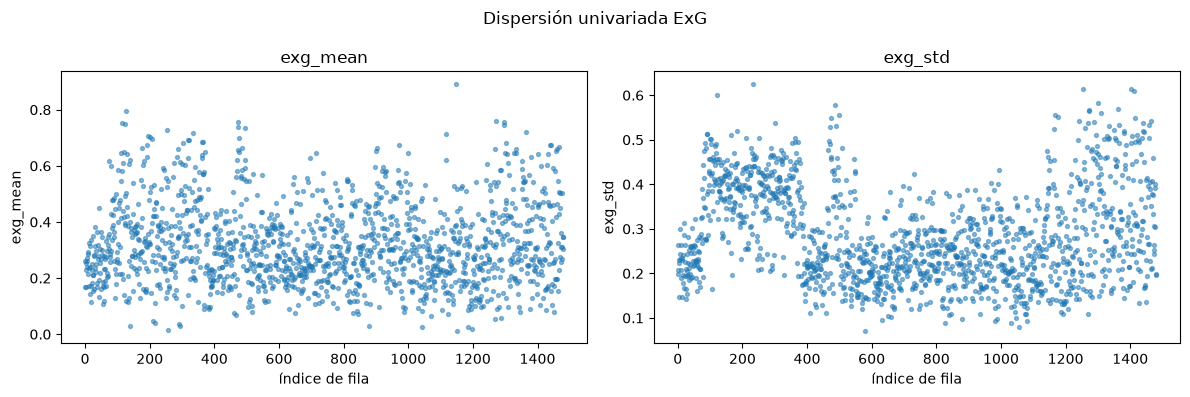

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-exg-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-exg-scatter.png')

In [35]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
row_index = np.arange(len(leaf_features))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada ExG")
fig.tight_layout()
exg_scatter_path = results_dir / "rocole-featured-exg-scatter.png"
fig.savefig(exg_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", exg_scatter_path)
exg_scatter_path


Ahora las cajas de NGRDI (ngrdi_mean, ngrdi_std), misma mirada univariada.


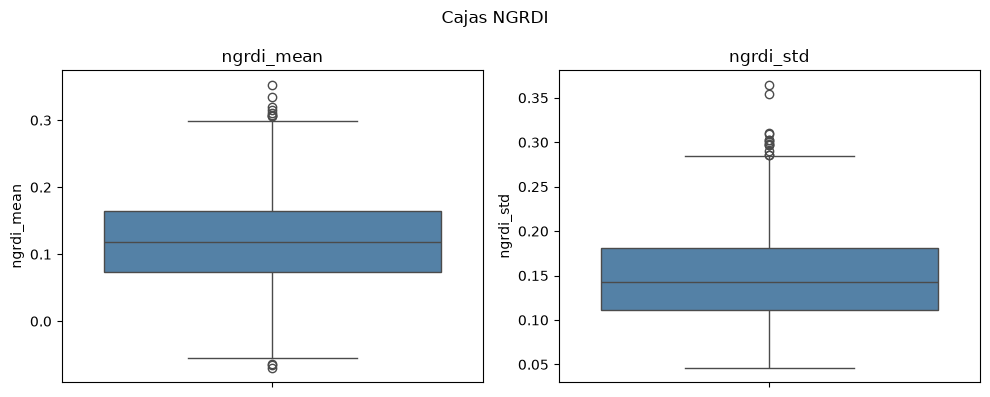

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-ngrdi-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-ngrdi-boxplots.png')

In [36]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas NGRDI")
fig.tight_layout()
ngrdi_box_path = results_dir / "rocole-featured-ngrdi-boxplots.png"
fig.savefig(ngrdi_box_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", ngrdi_box_path)
ngrdi_box_path


Dispersión univariada de NGRDI, una hoja por punto.


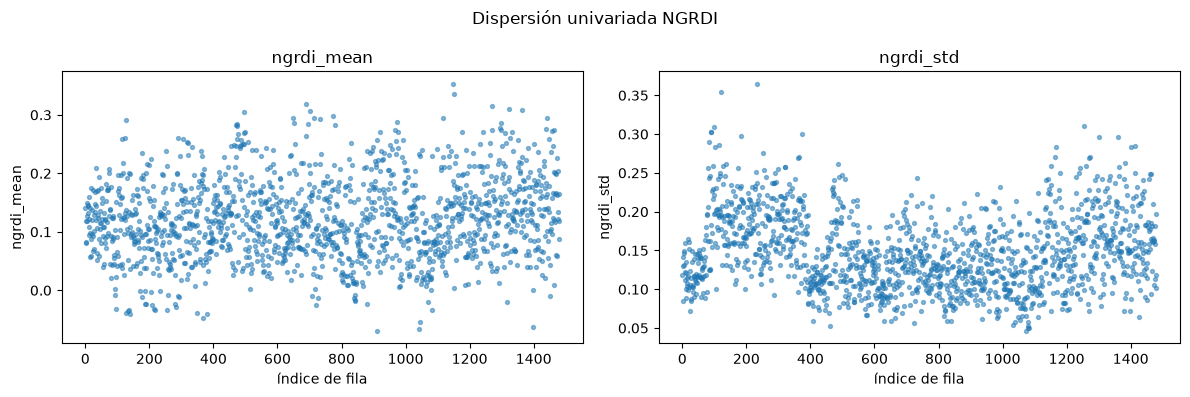

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-ngrdi-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-ngrdi-scatter.png')

In [37]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada NGRDI")
fig.tight_layout()
ngrdi_scatter_path = results_dir / "rocole-featured-ngrdi-scatter.png"
fig.savefig(ngrdi_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", ngrdi_scatter_path)
ngrdi_scatter_path


Cajas de VARI (vari_mean, vari_std). Pueden verse aplastadas por extremos; aquí solo miramos, sin decidir todavía.


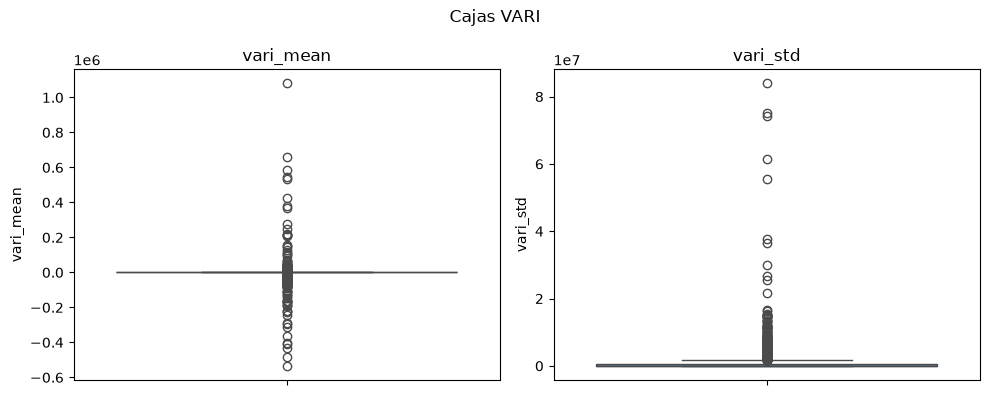

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-vari-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-vari-boxplots.png')

In [38]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["vari_mean", "vari_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas VARI")
fig.tight_layout()
vari_box_path = results_dir / "rocole-featured-vari-boxplots.png"
fig.savefig(vari_box_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", vari_box_path)
vari_box_path


Dispersión univariada de VARI. Los extremos saltan a la vista; seguimos observando.


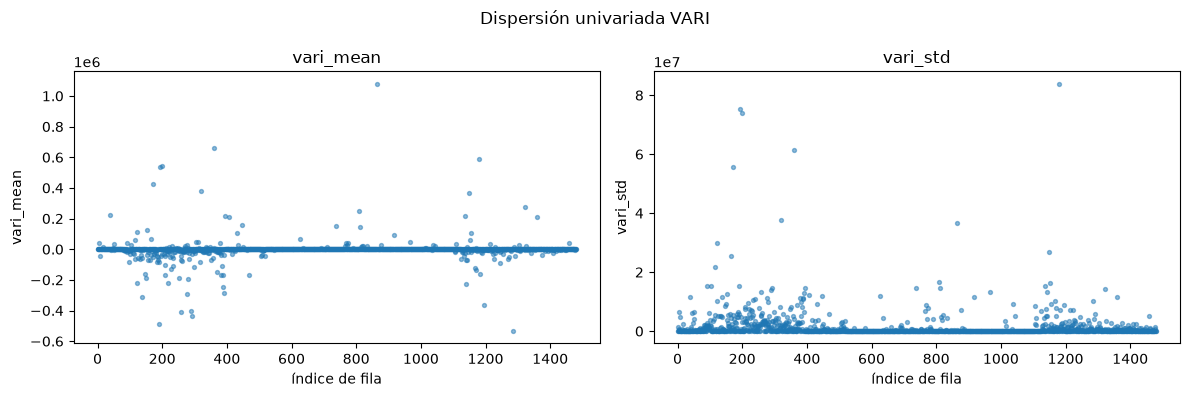

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-vari-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-vari-scatter.png')

In [39]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column in zip(axes, ["vari_mean", "vari_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada VARI")
fig.tight_layout()
vari_scatter_path = results_dir / "rocole-featured-vari-scatter.png"
fig.savefig(vari_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", vari_scatter_path)
vari_scatter_path


Documentamos VARI en train con percentiles y extremos. La mediana suele verse razonable; las colas confirman el artefacto del denominador.


In [40]:
# Entrada
# leaf_features, seed

# Qué hacemos
train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()
percentile_levels = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
vari_mean_percentiles = train_leaves["vari_mean"].quantile(percentile_levels)
vari_std_percentiles = train_leaves["vari_std"].quantile(percentile_levels)
vari_mean_extremes = {
    "min": float(train_leaves["vari_mean"].min()),
    "max": float(train_leaves["vari_mean"].max()),
    "min_file": train_leaves.loc[train_leaves["vari_mean"].idxmin(), "File"],
    "max_file": train_leaves.loc[train_leaves["vari_mean"].idxmax(), "File"],
}
vari_std_extremes = {
    "min": float(train_leaves["vari_std"].min()),
    "max": float(train_leaves["vari_std"].max()),
    "min_file": train_leaves.loc[train_leaves["vari_std"].idxmin(), "File"],
    "max_file": train_leaves.loc[train_leaves["vari_std"].idxmax(), "File"],
}

# Salida
print("train filas:", len(train_leaves))
print("\nvari_mean percentiles:")
print(vari_mean_percentiles)
print("\nvari_mean extremos:", vari_mean_extremes)
print("\nvari_std percentiles:")
print(vari_std_percentiles)
print("\nvari_std extremos:", vari_std_extremes)
vari_mean_percentiles


train filas: 1037

vari_mean percentiles:
0.01   -165524.155351
0.05    -31633.382825
0.25       -42.147205
0.50         0.138296
0.75         0.238771
0.95      5496.974281
0.99    155232.389801
Name: vari_mean, dtype: float64

vari_mean extremos: {'min': -534227.0993984542, 'max': 1079861.2813293056, 'min_file': 'C10P39E2.jpg', 'max_file': 'C7P30E2.jpg'}

vari_std percentiles:
0.01    8.957814e-02
0.05    1.146346e-01
0.25    1.566947e-01
0.50    2.168718e-01
0.75    6.221368e+05
0.95    6.463074e+06
0.99    1.517300e+07
Name: vari_std, dtype: float64

vari_std extremos: {'min': 0.06219724278524323, 'max': 75266590.57579298, 'min_file': 'C9P14E2.jpg', 'max_file': 'C3P8H1.jpg'}


0.01   -165524.155351
0.05    -31633.382825
0.25       -42.147205
0.50         0.138296
0.75         0.238771
0.95      5496.974281
0.99    155232.389801
Name: vari_mean, dtype: float64

Con esa evidencia dejamos documentada la decisión: retirar las columnas VARI del protocolo de modelado principal. El CSV las puede conservar; los modelos 04 y 05 no las usan.


In [41]:
# Entrada
# evidencia de percentiles y figuras VARI

# Qué hacemos
vari_feature_decision = "drop_vari"

# Salida
print("vari_feature_decision:", vari_feature_decision)
vari_feature_decision


vari_feature_decision: drop_vari


'drop_vari'

Cajas de las tres medidas GLCM: contraste, homogeneidad y energía.


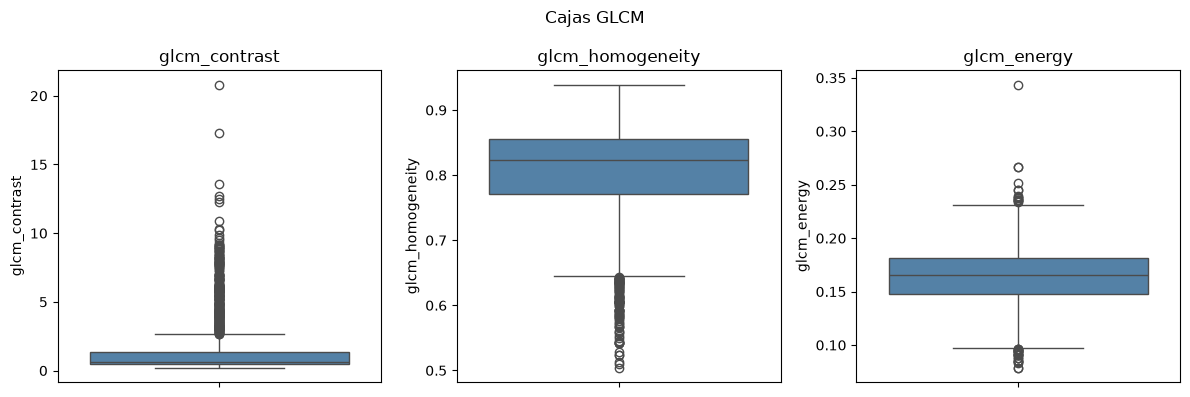

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-glcm-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-glcm-boxplots.png')

In [42]:
# Entrada
# leaf_features

# Qué hacemos
glcm_columns = ["glcm_contrast", "glcm_homogeneity", "glcm_energy"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, column in zip(axes, glcm_columns):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas GLCM")
fig.tight_layout()
glcm_box_path = results_dir / "rocole-featured-glcm-boxplots.png"
fig.savefig(glcm_box_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", glcm_box_path)
glcm_box_path


Dispersión univariada de las medidas GLCM.


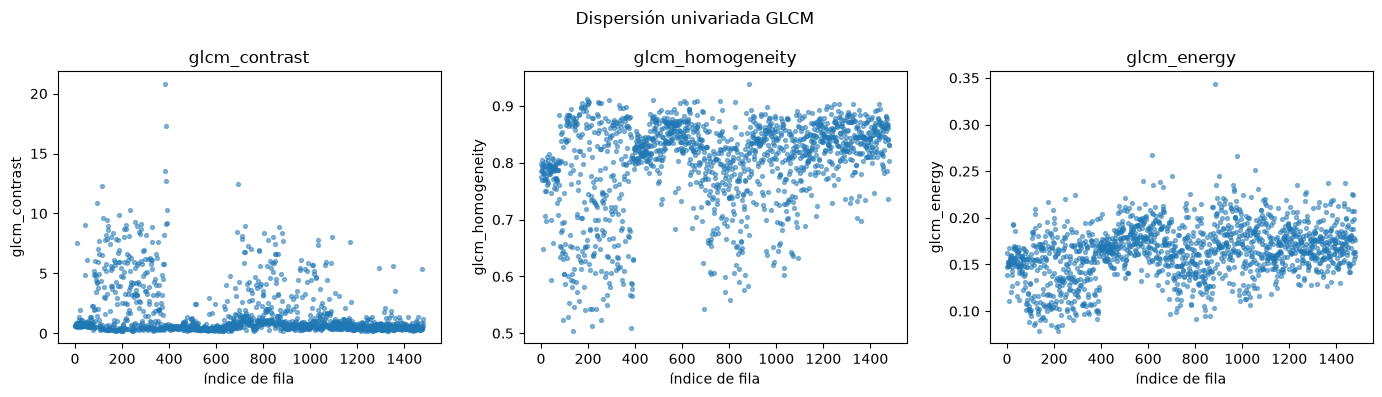

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-glcm-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-glcm-scatter.png')

In [43]:
# Entrada
# leaf_features

# Qué hacemos
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, glcm_columns):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada GLCM")
fig.tight_layout()
glcm_scatter_path = results_dir / "rocole-featured-glcm-scatter.png"
fig.savefig(glcm_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", glcm_scatter_path)
glcm_scatter_path


Hasta aquí: carga, duplicados, nulos, no finitos, mirada univariada y decisión de retirar VARI. Siguiente: comparar sanas y afectadas en train.


Comparamos hojas sanas y afectadas solo con train. VARI queda fuera de esta mirada.


Nos quedamos con las filas de aprender (split igual a train), si aún no estaban apartadas.


In [44]:
# Entrada
# leaf_features

# Qué hacemos
train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()

# Salida
print("train filas:", len(train_leaves))
train_leaves.head()


train filas: 1037


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


Contamos cuántas hojas de train hay por Binary.Label (sana frente a afectada).


In [45]:
# Entrada
# train_leaves

# Qué hacemos
train_label_counts = train_leaves["Binary.Label"].value_counts()

# Salida
print(train_label_counts)
train_label_counts


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64

Elegimos las columnas a comparar por clase: ExG, NGRDI y GLCM. Sin VARI.


In [46]:
# Entrada
# ninguna

# Qué hacemos
comparison_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

# Salida
comparison_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

Miramos ExG (exg_mean, exg_std) con cajas lado a lado por Binary.Label, solo en train.


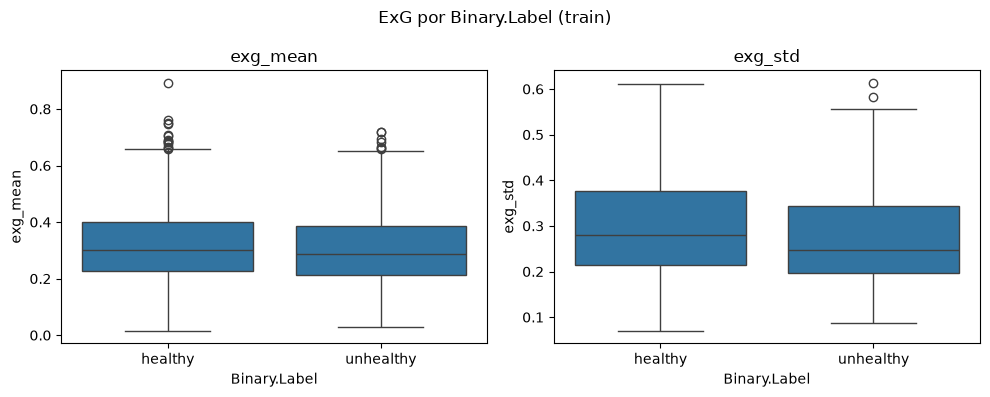

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-exg-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-exg-by-label-boxplots.png')

In [47]:
# Entrada
# train_leaves

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("ExG por Binary.Label (train)")
fig.tight_layout()
exg_by_label_path = results_dir / "rocole-featured-exg-by-label-boxplots.png"
fig.savefig(exg_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", exg_by_label_path)
exg_by_label_path


Lectura ExG: mira la figura. Si las cajas se solapan mucho, las clases se mezclan en esa medida; si se apartan un poco, hay alguna diferencia visual. No es aún un veredicto de predicción.


Misma comparación con NGRDI (ngrdi_mean, ngrdi_std) por Binary.Label en train.


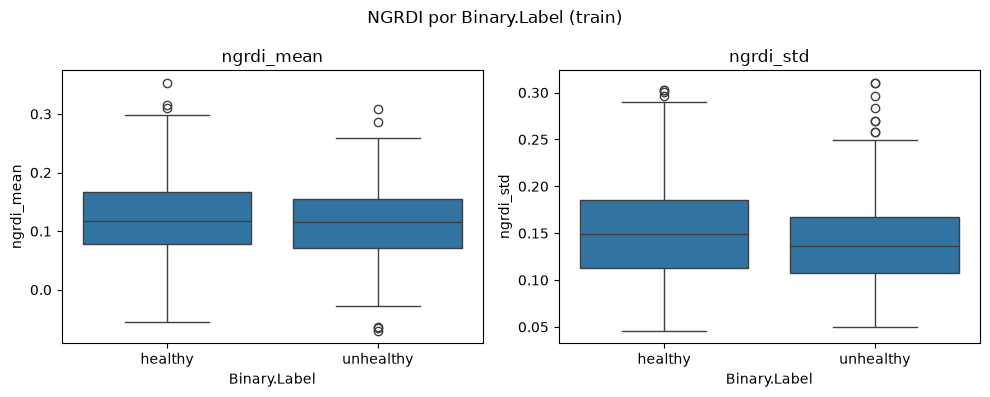

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-ngrdi-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-ngrdi-by-label-boxplots.png')

In [48]:
# Entrada
# train_leaves

# Qué hacemos
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("NGRDI por Binary.Label (train)")
fig.tight_layout()
ngrdi_by_label_path = results_dir / "rocole-featured-ngrdi-by-label-boxplots.png"
fig.savefig(ngrdi_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", ngrdi_by_label_path)
ngrdi_by_label_path


Lectura NGRDI: otra vez, mira el solape o la separación de las cajas. Es una lectura visual; no es un ranking de variables.


Ahora las tres medidas GLCM (contraste, homogeneidad, energía) por clase en train.


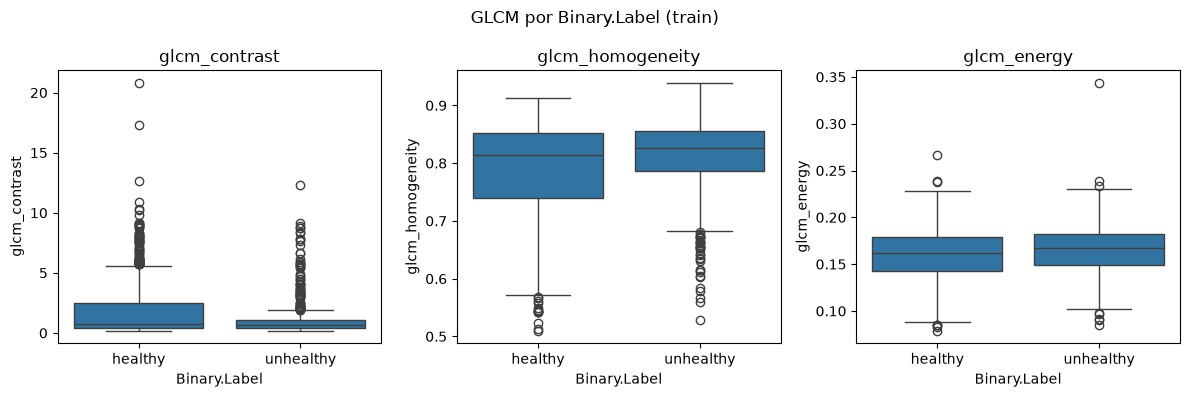

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-glcm-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-glcm-by-label-boxplots.png')

In [49]:
# Entrada
# train_leaves

# Qué hacemos
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, column in zip(axes, ["glcm_contrast", "glcm_homogeneity", "glcm_energy"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("GLCM por Binary.Label (train)")
fig.tight_layout()
glcm_by_label_path = results_dir / "rocole-featured-glcm-by-label-boxplots.png"
fig.savefig(glcm_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", glcm_by_label_path)
glcm_by_label_path


Lectura GLCM: observa si alguna medida se aparta un poco entre clases o si casi todo se solapa. Seguimos sin elegir predictoras.


Vimos solape o separación a ojo entre sanas y afectadas en train (ExG, NGRDI, GLCM; sin VARI). Aún no elegimos variables ni medimos acierto.


Por último, comprobamos en train que etiqueta, split y link_group coinciden con el índice featured, fila a fila por File.


In [50]:
# Entrada
# train_leaves

# Qué hacemos
index_path = repo_root / "data" / "featured" / "rocole" / "index.csv"
featured_index = pd.read_csv(index_path)
train_with_index = train_leaves.merge(
    featured_index[["File", "Binary.Label", "split", "link_group"]],
    on="File",
    how="left",
    suffixes=("_feat", "_index"),
)
label_match = (
    train_with_index["Binary.Label_feat"] == train_with_index["Binary.Label_index"]
).all()
split_match = (train_with_index["split_feat"] == train_with_index["split_index"]).all()
link_match = (
    train_with_index["link_group_feat"] == train_with_index["link_group_index"]
).all()
missing_in_index = int(train_with_index["split_index"].isna().sum())
index_integrity = {
    "train_rows": len(train_leaves),
    "merged_rows": len(train_with_index),
    "missing_in_index": missing_in_index,
    "Binary.Label_match": bool(label_match),
    "split_match": bool(split_match),
    "link_group_match": bool(link_match),
}

# Salida
print(index_integrity)
index_integrity


{'train_rows': 1037, 'merged_rows': 1037, 'missing_in_index': 0, 'Binary.Label_match': True, 'split_match': True, 'link_group_match': True}


{'train_rows': 1037,
 'merged_rows': 1037,
 'missing_in_index': 0,
 'Binary.Label_match': True,
 'split_match': True,
 'link_group_match': True}

Antes de cerrar, miramos relaciones entre medidas y con la etiqueta. Solo hojas de aprender, sin VARI (ya quedó drop_vari). Las cajas ya se solapaban; aquí observamos, no elegimos predictoras fuertes.


Pasamos la etiqueta binaria a números para poder correlacionar: sana vale 0 y afectada vale 1.


In [51]:
# Entrada
# train_leaves

# Qué hacemos
binary_label_code = train_leaves["Binary.Label"].map(
    {"healthy": 0, "unhealthy": 1}
)

# Salida
print(binary_label_code.value_counts(dropna=False))
binary_label_code


Binary.Label
0    530
1    507
Name: count, dtype: int64


0       0
1       1
2       0
3       0
4       1
       ..
1475    0
1476    1
1477    0
1478    1
1479    1
Name: Binary.Label, Length: 1037, dtype: int64

Armamos una tabla de train con las siete medidas ya usadas en la comparación por clase (ExG, NGRDI y GLCM) más el código 0/1. Sin columnas VARI.


In [52]:
# Entrada
# train_leaves, comparison_columns, binary_label_code

# Qué hacemos
if "comparison_columns" not in globals():
    comparison_columns = [
        "exg_mean",
        "exg_std",
        "ngrdi_mean",
        "ngrdi_std",
        "glcm_contrast",
        "glcm_homogeneity",
        "glcm_energy",
    ]

correlation_leaves = train_leaves[comparison_columns].copy()
correlation_leaves["binary_label_code"] = binary_label_code.to_numpy()

# Salida
correlation_leaves.head()


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy,binary_label_code
0,0.261530,0.206835,0.141426,0.118705,0.603388,0.798073,0.161943,0
1,0.167154,0.198152,0.082722,0.129672,0.739996,0.774939,0.139027,1
2,0.229394,0.264305,0.118196,0.141937,0.638387,0.784853,0.147145,0
3,0.167927,0.147516,0.081697,0.085211,0.590025,0.785764,0.152910,0
4,0.253770,0.231036,0.118870,0.146720,0.614583,0.805190,0.149165,1


Correlación de cada medida con el código de etiqueta. Miramos magnitud y signo; no es un ranking de variables predictoras.


In [53]:
# Entrada
# correlation_leaves

# Qué hacemos
feature_label_correlation = correlation_leaves[comparison_columns].corrwith(
    correlation_leaves["binary_label_code"]
)

# Salida
print(feature_label_correlation)
feature_label_correlation


exg_mean           -0.047637
exg_std            -0.125759
ngrdi_mean         -0.048981
ngrdi_std          -0.118150
glcm_contrast      -0.188690
glcm_homogeneity    0.153338
glcm_energy         0.113158
dtype: float64


exg_mean           -0.047637
exg_std            -0.125759
ngrdi_mean         -0.048981
ngrdi_std          -0.118150
glcm_contrast      -0.188690
glcm_homogeneity    0.153338
glcm_energy         0.113158
dtype: float64

Lee esos números. Si salen bajos o cerca de cero, encaja con el solape de las cajas. No digas que una medida predice bien.


Ahora la relación entre medidas: matriz de correlación solo entre las siete características, sin la etiqueta.


In [54]:
# Entrada
# correlation_leaves, comparison_columns

# Qué hacemos
feature_correlation_matrix = correlation_leaves[comparison_columns].corr()

# Salida
feature_correlation_matrix


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
exg_mean,1.000000,0.679803,0.799004,0.543281,-0.226416,0.335257,0.254930
exg_std,0.679803,1.000000,0.423256,0.915640,0.143940,-0.074793,-0.179511
ngrdi_mean,0.799004,0.423256,1.000000,0.399294,-0.373942,0.469448,0.431358
ngrdi_std,0.543281,0.915640,0.399294,1.000000,0.204307,-0.148091,-0.236250
glcm_contrast,-0.226416,0.143940,-0.373942,0.204307,1.000000,-0.889006,-0.708511
glcm_homogeneity,0.335257,-0.074793,0.469448,-0.148091,-0.889006,1.000000,0.846449
glcm_energy,0.254930,-0.179511,0.431358,-0.236250,-0.708511,0.846449,1.000000


Pintamos esa matriz como mapa de calor para ver qué medidas van juntas.


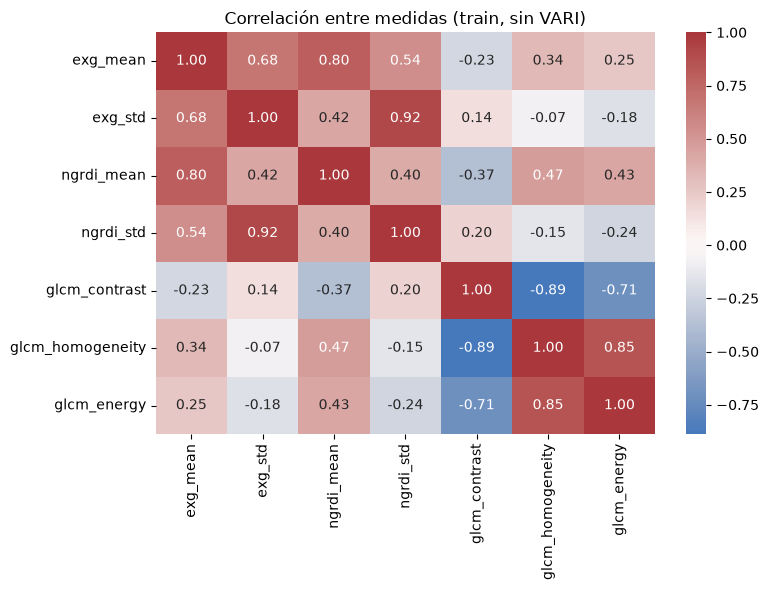

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-feature-corr-heatmap.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-feature-corr-heatmap.png')

In [55]:
# Entrada
# feature_correlation_matrix

# Qué hacemos
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    feature_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=ax,
)
ax.set_title("Correlación entre medidas (train, sin VARI)")
fig.tight_layout()
feature_corr_heatmap_path = results_dir / "rocole-featured-feature-corr-heatmap.png"
fig.savefig(feature_corr_heatmap_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", feature_corr_heatmap_path)
feature_corr_heatmap_path


Para no saturar la figura, elegimos unas pocas medidas de familias distintas: media de ExG, media de NGRDI y contraste GLCM.


In [56]:
# Entrada
# comparison_columns

# Qué hacemos
pair_feature_columns = ["exg_mean", "ngrdi_mean", "glcm_contrast"]

# Salida
pair_feature_columns


['exg_mean', 'ngrdi_mean', 'glcm_contrast']

Gráficos de pares solo con ese subconjunto, en train, coloreados por sana/afectada.


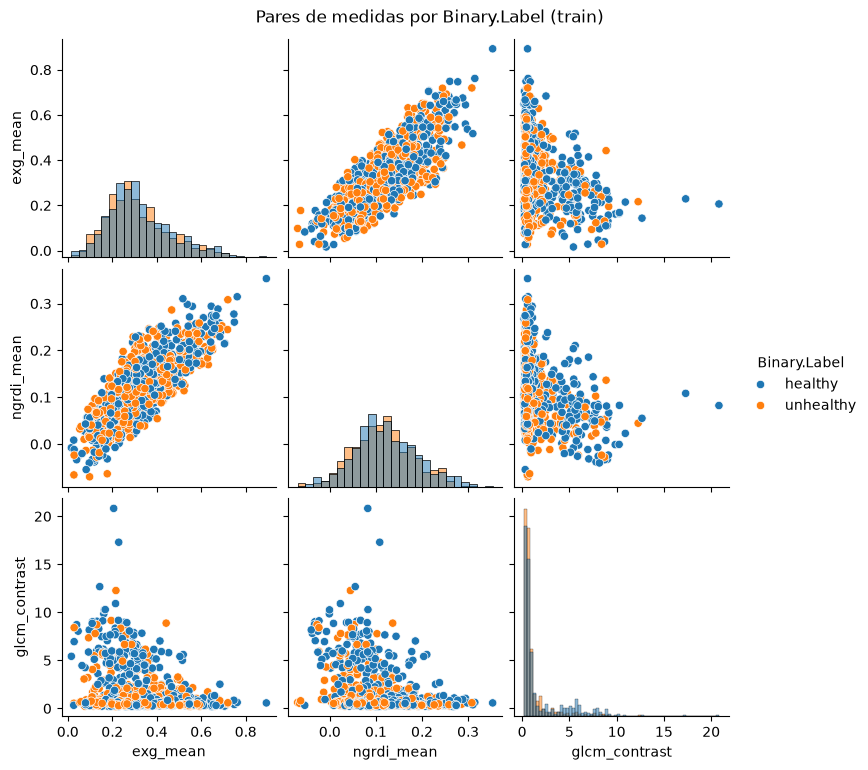

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-feature-pairs.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-feature-pairs.png')

In [57]:
# Entrada
# correlation_leaves, pair_feature_columns

# Qué hacemos
pair_plot_data = correlation_leaves[pair_feature_columns].copy()
pair_plot_data["Binary.Label"] = correlation_leaves["binary_label_code"].map(
    {0: "healthy", 1: "unhealthy"}
)
pair_grid = sns.pairplot(
    pair_plot_data,
    vars=pair_feature_columns,
    hue="Binary.Label",
    diag_kind="hist",
)
pair_grid.fig.suptitle("Pares de medidas por Binary.Label (train)", y=1.02)
feature_pairs_path = results_dir / "rocole-featured-feature-pairs.png"
pair_grid.savefig(feature_pairs_path, dpi=120, bbox_inches="tight")
plt.show()

# Salida
print("figura:", feature_pairs_path)
feature_pairs_path


Observa si las nubes de sana y afectada se mezclan. Seguimos sin coronar predictoras; el solape visual es el mensaje.


## Cierre

Checklist:
- Duplicados, nulos y no finitos revisados; las nueve medidas salen limpias en sentido de NaN/Inf.
- VARI queda documentada (percentiles y extremos) y se retira del modelado principal.
- En train, las cajas por clase se solapan en ExG, NGRDI y GLCM.
- Correlaciones y pares en train, sin VARI, muestran solapes o asociaciones débiles; no declaramos predictoras fuertes.
- Etiqueta, split y link_group coinciden con el índice por File.

Siguiente: cuadernos 04 y 05, sin columnas VARI.
